In [1]:
print("Hello Gayatri")

Hello Gayatri


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import nltk
from wordcloud import WordCloud

print("All libraries are working!")

All libraries are working!


In [3]:
import nltk

nltk.download('twitter_samples')

[nltk_data] Downloading package twitter_samples to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\twitter_samples.zip.


True

In [4]:
from nltk.corpus import twitter_samples

positive_tweets = twitter_samples.strings('positive_tweets.json')
negative_tweets = twitter_samples.strings('negative_tweets.json')

print("Positive tweets:", len(positive_tweets))
print("Negative tweets:", len(negative_tweets))

Positive tweets: 5000
Negative tweets: 5000


In [5]:
import pandas as pd

# Create positive and negative data
positive_df = pd.DataFrame({
    'text': positive_tweets,
    'sentiment': 1
})

negative_df = pd.DataFrame({
    'text': negative_tweets,
    'sentiment': 0
})

# Combine both datasets
df = pd.concat([positive_df, negative_df], ignore_index=True)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (10000, 2)

First 5 rows:


,text,sentiment
0,#FollowFriday @France_Inte @PKuchly57 @Milipol...,1
1,@Lamb2ja Hey James! How odd :/ Please call our...,1
2,@DespiteOfficial we had a listen last night :)...,1
3,@97sides CONGRATS :),1
4,yeaaaah yippppy!!! my accnt verified rqst has...,1


In [6]:
print("Dataset Information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment counts:")
print(df['sentiment'].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   text       10000 non-null  str  
 1   sentiment  10000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 156.4 KB
None

Missing values:
text         0
sentiment    0
dtype: int64

Sentiment counts:
sentiment
1    5000
0    5000
Name: count, dtype: int64


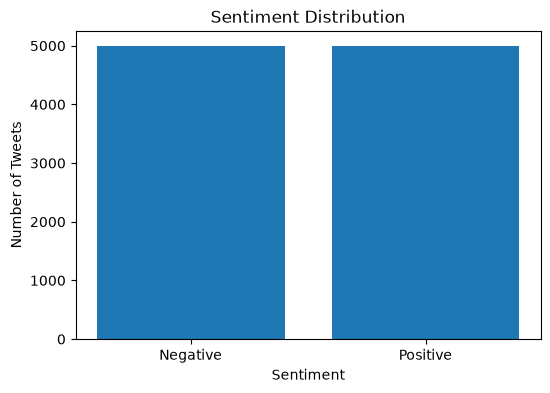

In [7]:
import matplotlib.pyplot as plt

sentiment_counts = df['sentiment'].value_counts()

plt.figure(figsize=(6, 4))

plt.bar(
    ['Negative', 'Positive'],
    [sentiment_counts[0], sentiment_counts[1]]
)

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')

plt.show()

In [8]:
import re

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    
    # Remove @mentions
    text = re.sub(r'@\w+', '', text)
    
    # Remove hashtag symbol but keep the word
    text = re.sub(r'#', '', text)
    
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [9]:
test_text = "@John I LOVE this movie!!! 😍 https://example.com #Amazing"

print("Before:")
print(test_text)

print("\nAfter:")
print(clean_text(test_text))

Before:
@John I LOVE this movie!!! 😍 https://example.com #Amazing

After:
i love this movie amazing


In [10]:
df['clean_text'] = df['text'].apply(clean_text)

print(df[['text', 'clean_text', 'sentiment']].head())

                                                text  \
0  #FollowFriday @France_Inte @PKuchly57 @Milipol...   
1  @Lamb2ja Hey James! How odd :/ Please call our...   
2  @DespiteOfficial we had a listen last night :)...   
3                               @97sides CONGRATS :)   
4  yeaaaah yippppy!!!  my accnt verified rqst has...   

                                          clean_text  sentiment  
0  followfriday for being top engaged members in ...          1  
1  hey james how odd please call our contact cent...          1  
2  we had a listen last night as you bleed is an ...          1  
3                                           congrats          1  
4  yeaaaah yippppy my accnt verified rqst has suc...          1  


In [11]:
import nltk

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [12]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Keep important negative words
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

print("Number of stopwords:", len(stop_words))

Number of stopwords: 195


In [13]:
def remove_stopwords(text):
    words = text.split()
    
    filtered_words = [
        word for word in words
        if word not in stop_words
    ]
    
    return ' '.join(filtered_words)

df['processed_text'] = df['clean_text'].apply(remove_stopwords)

print(df[['text', 'clean_text', 'processed_text', 'sentiment']].head())

                                                text  \
0  #FollowFriday @France_Inte @PKuchly57 @Milipol...   
1  @Lamb2ja Hey James! How odd :/ Please call our...   
2  @DespiteOfficial we had a listen last night :)...   
3                               @97sides CONGRATS :)   
4  yeaaaah yippppy!!!  my accnt verified rqst has...   

                                          clean_text  \
0  followfriday for being top engaged members in ...   
1  hey james how odd please call our contact cent...   
2  we had a listen last night as you bleed is an ...   
3                                           congrats   
4  yeaaaah yippppy my accnt verified rqst has suc...   

                                      processed_text  sentiment  
0    followfriday top engaged members community week          1  
1  hey james odd please call contact centre able ...          1  
2     listen last night bleed amazing track scotland          1  
3                                           congrats          

In [14]:
print("Original:")
print(df['text'].iloc[0])

print("\nProcessed:")
print(df['processed_text'].iloc[0])

Original:
#FollowFriday @France_Inte @PKuchly57 @Milipol_Paris for being top engaged members in my community this week :)

Processed:
followfriday top engaged members community week


In [15]:
from sklearn.model_selection import train_test_split

X = df['processed_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (8000, 5000)
Testing data shape: (2000, 5000)


In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [18]:
# Make predictions on test data
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed!
First 10 predictions:
[1 0 1 1 0 0 0 1 1 1]


In [19]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.7655
Accuracy percentage: 76.55 %


In [20]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))

              precision    recall  f1-score   support

    Negative       0.75      0.80      0.77      1000
    Positive       0.78      0.73      0.76      1000

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.77      0.77      0.77      2000



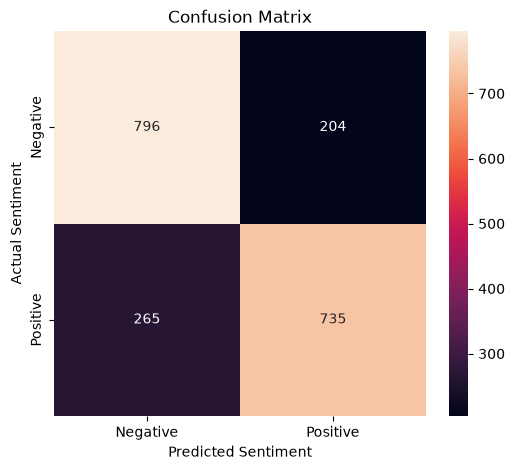

In [21]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

In [22]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Model 2: Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Model 3: Linear SVM
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)

# Model 4: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_tfidf, y_train)

print("All 4 models trained successfully!")

All 4 models trained successfully!


In [23]:
# Predictions from all models

lr_pred = model.predict(X_test_tfidf)
nb_pred = nb_model.predict(X_test_tfidf)
svm_pred = svm_model.predict(X_test_tfidf)
rf_pred = rf_model.predict(X_test_tfidf)

print("Predictions completed for all models!")

Predictions completed for all models!


In [24]:
from sklearn.metrics import accuracy_score

results = {
    'Logistic Regression': accuracy_score(y_test, lr_pred),
    'Naive Bayes': accuracy_score(y_test, nb_pred),
    'Linear SVM': accuracy_score(y_test, svm_pred),
    'Random Forest': accuracy_score(y_test, rf_pred)
}

for model_name, score in results.items():
    print(model_name, ":", round(score * 100, 2), "%")

Logistic Regression : 76.55 %
Naive Bayes : 75.5 %
Linear SVM : 74.35 %
Random Forest : 73.3 %


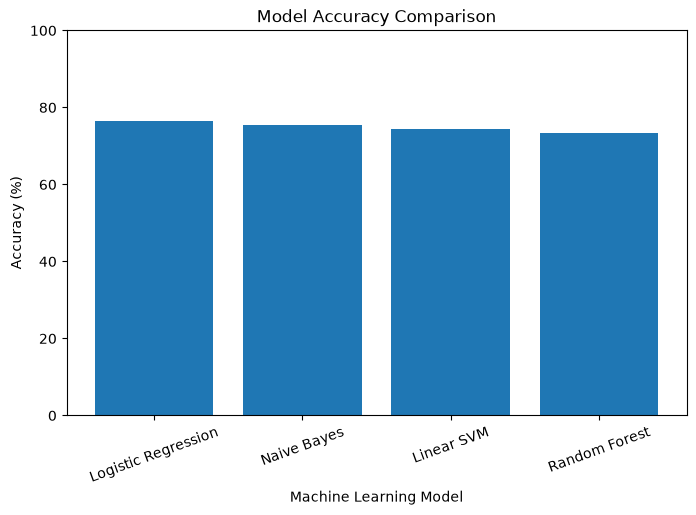

In [25]:
plt.figure(figsize=(8, 5))

model_names = list(results.keys())
accuracies = [score * 100 for score in results.values()]

plt.bar(model_names, accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy (%)')

plt.xticks(rotation=20)
plt.ylim(0, 100)

plt.show()

In [26]:
best_model_name = max(results, key=results.get)
best_accuracy = results[best_model_name]

print("Best Model:", best_model_name)
print("Best Accuracy:", round(best_accuracy * 100, 2), "%")

Best Model: Logistic Regression
Best Accuracy: 76.55 %


In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

# Probability of positive sentiment
y_prob = model.predict_proba(X_test_tfidf)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

print("AUC Score:", round(auc_score, 3))

AUC Score: 0.842


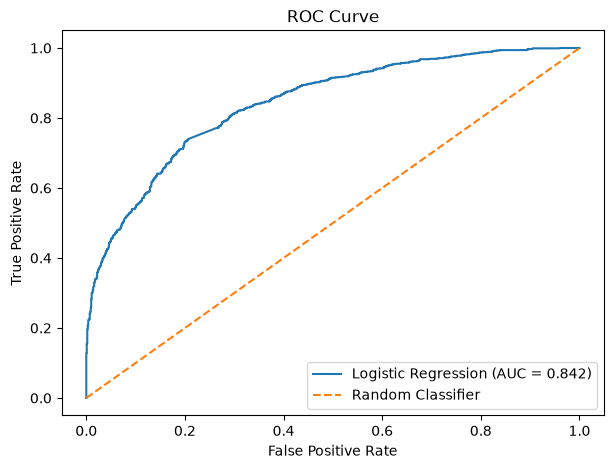

In [28]:
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {auc_score:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.show()

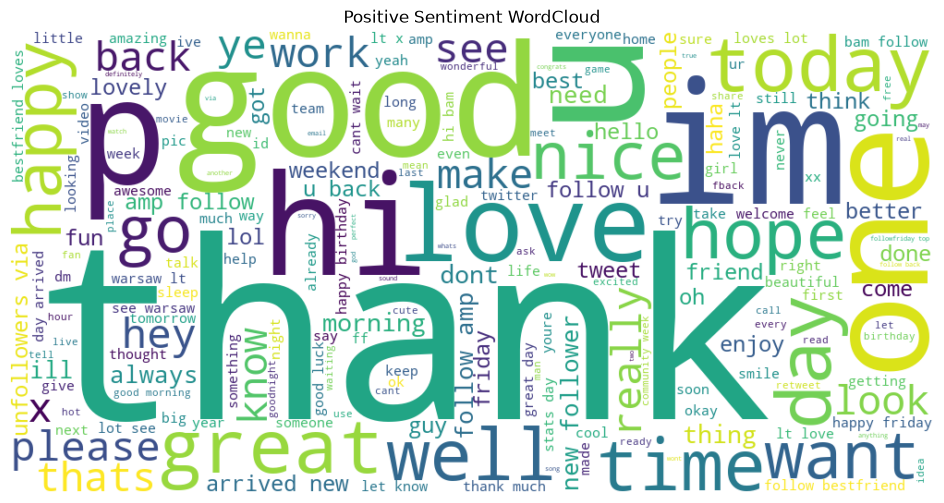

In [29]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

positive_text = " ".join(
    df[df['sentiment'] == 1]['processed_text']
)

positive_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(positive_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Sentiment WordCloud')
plt.show()

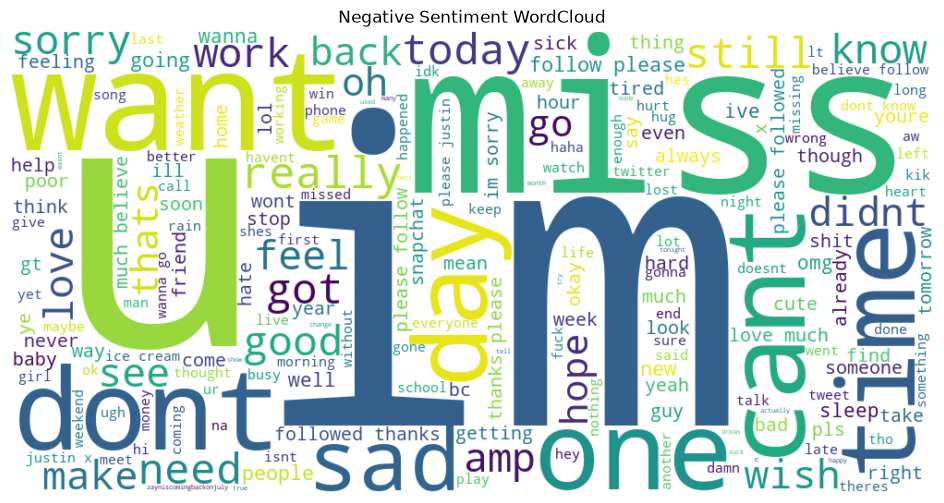

In [30]:
negative_text = " ".join(
    df[df['sentiment'] == 0]['processed_text']
)

negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Sentiment WordCloud')
plt.show()

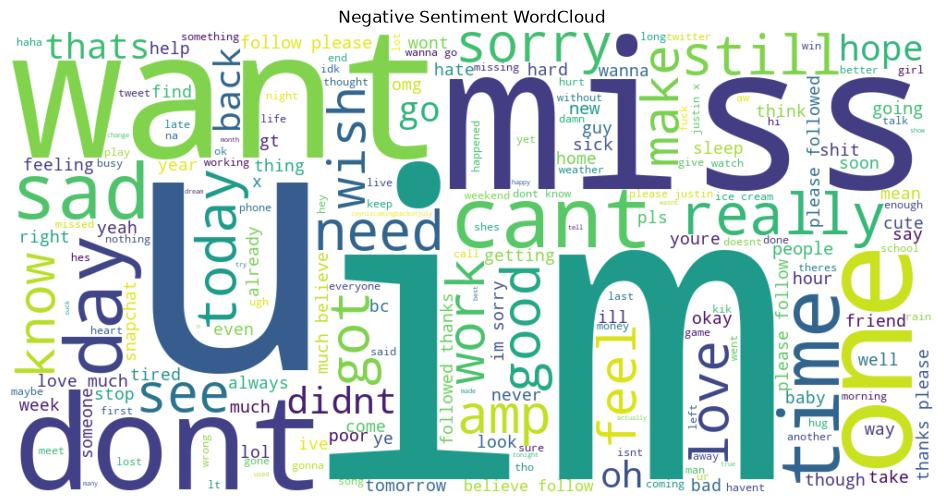

In [31]:
negative_text = " ".join(
    df[df['sentiment'] == 0]['processed_text']
)

negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Sentiment WordCloud')
plt.show()

In [32]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    processed = remove_stopwords(cleaned)
    
    text_vector = tfidf.transform([processed])
    prediction = model.predict(text_vector)[0]
    
    if prediction == 1:
        return "Positive 😊"
    else:
        return "Negative 😞"

In [33]:
text = "I absolutely love this product, it is amazing!"

print("Text:", text)
print("Prediction:", predict_sentiment(text))

Text: I absolutely love this product, it is amazing!
Prediction: Positive 😊


In [34]:
text = "This is the worst product, I hate it!"

print("Text:", text)
print("Prediction:", predict_sentiment(text))

Text: This is the worst product, I hate it!
Prediction: Negative 😞


In [35]:
from sklearn.linear_model import LogisticRegression

# Train final Logistic Regression model
final_model = LogisticRegression(max_iter=1000)

final_model.fit(X_train_tfidf, y_train)

print("Final Logistic Regression model trained successfully!")

Final Logistic Regression model trained successfully!


In [36]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_final = final_model.predict(X_test_tfidf)

final_accuracy = accuracy_score(y_test, y_pred_final)

print("Final Model Accuracy:", round(final_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["Negative", "Positive"]
))

Final Model Accuracy: 76.55 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.80      0.77      1000
    Positive       0.78      0.73      0.76      1000

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.77      0.77      0.77      2000



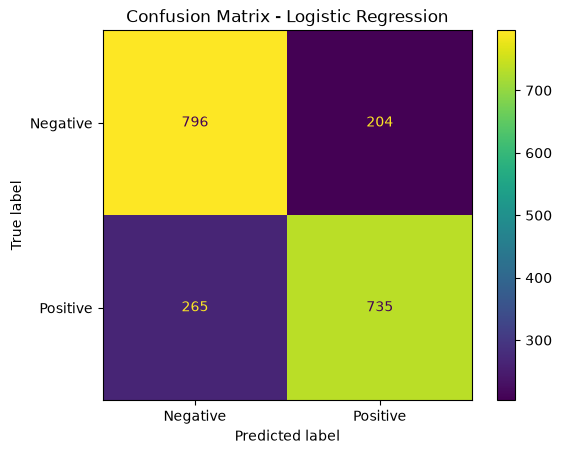

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [38]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    processed = remove_stopwords(cleaned)

    text_vector = tfidf.transform([processed])

    prediction = final_model.predict(text_vector)[0]

    if prediction == 1:
        return "Positive 😊"
    else:
        return "Negative 😞"

In [39]:
text = "I absolutely love this product, it is amazing!"

print("Text:", text)
print("Prediction:", predict_sentiment(text))

Text: I absolutely love this product, it is amazing!
Prediction: Positive 😊


In [40]:
text = "This is the worst product, I hate it!"

print("Text:", text)
print("Prediction:", predict_sentiment(text))

Text: This is the worst product, I hate it!
Prediction: Negative 😞


In [41]:
import joblib

joblib.dump(final_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!


In [42]:
df.to_csv("sentiment_analysis_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [43]:
import os

print("Files created:")
print(os.listdir())

Files created:
['.ipynb_checkpoints', 'desktop.ini', 'sentiment_analysis_dataset.csv', 'Sentiment_Analysis_Project.ipynb', 'sentiment_model.pkl', 'tfidf_vectorizer.pkl']


In [44]:
print("========== FINAL PROJECT RESULTS ==========")

print("Total Tweets:", len(df))
print("Positive Tweets:", (df['sentiment'] == 1).sum())
print("Negative Tweets:", (df['sentiment'] == 0).sum())

print("Final Model: Logistic Regression")
print("Final Accuracy:", round(final_accuracy * 100, 2), "%")

print("===========================================")

========== FINAL PROJECT RESULTS ==========
Total Tweets: 10000
Positive Tweets: 5000
Negative Tweets: 5000
Final Model: Logistic Regression
Final Accuracy: 76.55 %


In [45]:
print("==============================================")
print("        SENTIMENT ANALYSIS PROJECT")
print("==============================================")
print()
print("Dataset        : Twitter Sentiment Dataset")
print("Total Tweets   : 10,000")
print("Positive       : 5,000")
print("Negative       : 5,000")
print()
print("Text Processing: Cleaning + Stopword Removal")
print("Feature Method : TF-IDF")
print()
print("Models Used:")
print("1. Logistic Regression")
print("2. Naive Bayes")
print("3. Linear SVM")
print("4. Random Forest")
print()
print("Best Model     : Logistic Regression")
print("Accuracy       : 76.55%")
print()
print("Prediction Test:")
print("Positive Text  → Positive 😊")
print("Negative Text  → Negative 😞")
print()
print("==============================================")
print("             PROJECT COMPLETED")
print("==============================================")

        SENTIMENT ANALYSIS PROJECT

Dataset        : Twitter Sentiment Dataset
Total Tweets   : 10,000
Positive       : 5,000
Negative       : 5,000

Text Processing: Cleaning + Stopword Removal
Feature Method : TF-IDF

Models Used:
1. Logistic Regression
2. Naive Bayes
3. Linear SVM
4. Random Forest

Best Model     : Logistic Regression
Accuracy       : 76.55%

Prediction Test:
Positive Text  → Positive 😊
Negative Text  → Negative 😞

             PROJECT COMPLETED
